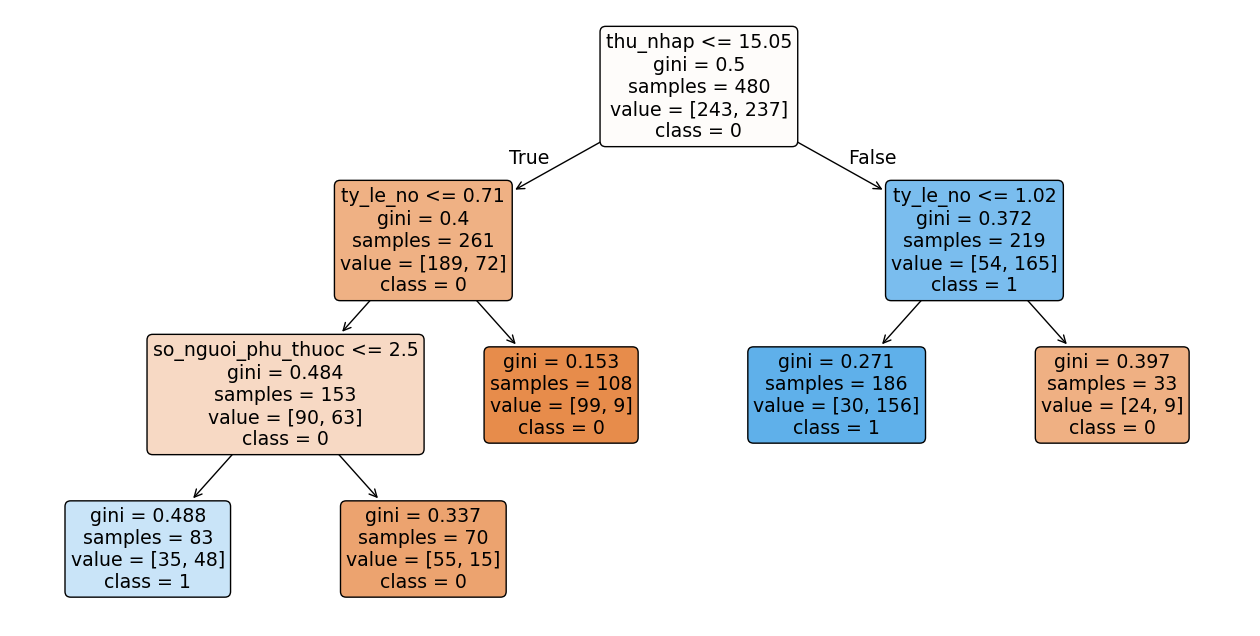

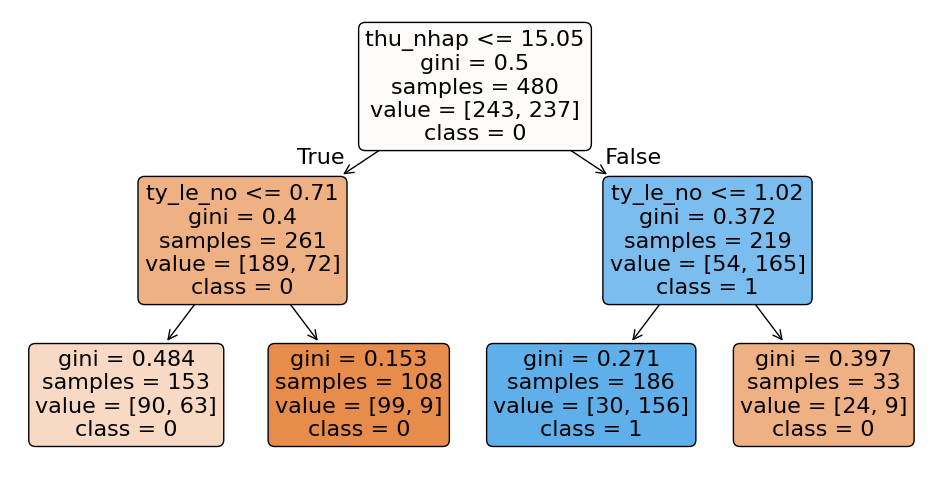

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder

# Đọc dữ liệu
df = pd.read_csv(
    "/Users/buixuankhanh/Documents/machine-learning/05_Caydinh/data/khach_vay.csv"
)

# Xóa khoảng trắng thừa trong tên cột
df.columns = df.columns.str.strip()

# Tách dữ liệu đầu vào và nhãn
X = df.drop(columns=["tra_dung_han"]).copy()
y = df["tra_dung_han"].copy()

# Mã hóa dữ liệu dạng chữ
for col in X.select_dtypes(include=["object", "category"]).columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

if y.dtype == "object" or isinstance(y.dtype, pd.CategoricalDtype):
    y = LabelEncoder().fit_transform(y.astype(str))

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Vẽ cây năm lá
cay_nam_la = DecisionTreeClassifier(
    max_leaf_nodes=5,
    random_state=42
)
cay_nam_la.fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(
    cay_nam_la,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in cay_nam_la.classes_],
    filled=True,
    rounded=True
)
plt.savefig("cay_nam_la.png", dpi=300, bbox_inches="tight")
plt.show()

# Vẽ cây sâu 2
cay_sau_2 = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)
cay_sau_2.fit(X_train, y_train)

plt.figure(figsize=(12, 6))
plot_tree(
    cay_sau_2,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in cay_sau_2.classes_],
    filled=True,
    rounded=True
)
plt.show()

nhận xét: Hai lá bên trái của cây sâu 2 có thể có cùng kết luận dự đoán, nhưng vẫn được chia thành hai nút vì điều kiện phân chia có thể làm giảm độ hỗn tạp Gini hoặc entropy. Mặc dù hai nút có cùng lớp dự đoán chiếm đa số, tỷ lệ của từng lớp trong hai nhóm vẫn có thể khác nhau. Cây quyết định vẫn giữ phép chia nếu nó đáp ứng tiêu chí phân chia và các điều kiện dừng của thuật toán.

In [10]:
#bài 2:
import numpy as np
import pandas as pd


def tinh_gini(y):
    """Tính chỉ số Gini của một nhóm dữ liệu."""
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1 - np.sum(p ** 2)


def gini_sau_chia(y, left_mask):
    """Tính Gini có trọng số sau khi chia dữ liệu."""
    y_left = y[left_mask]
    y_right = y[~left_mask]

    n = len(y)
    if n == 0:
        return 0

    return (
        len(y_left) / n * tinh_gini(y_left)
        + len(y_right) / n * tinh_gini(y_right)
    )


def tim_cau_hoi(X, y):
    """
    Thử mọi cột và mọi ngưỡng.
    Trả về cột, ngưỡng và độ giảm Gini lớn nhất.
    """
    if isinstance(X, pd.DataFrame):
        ten_cot = X.columns.tolist()
        X_array = X.to_numpy()
    else:
        X_array = np.asarray(X)
        ten_cot = [f"X[:, {i}]" for i in range(X_array.shape[1])]

    y = np.asarray(y)
    gini_goc = tinh_gini(y)

    giam_lon_nhat = -1
    cot_tot_nhat = None
    nguong_tot_nhat = None

    for j, ten in enumerate(ten_cot):
        # Chỉ xét các giá trị số
        gia_tri = X_array[:, j].astype(float)

        # Các ngưỡng nằm giữa hai giá trị liên tiếp khác nhau
        cac_gia_tri = np.sort(np.unique(gia_tri))
        cac_nguong = (cac_gia_tri[:-1] + cac_gia_tri[1:]) / 2

        for nguong in cac_nguong:
            left_mask = gia_tri <= nguong
            gini_con = gini_sau_chia(y, left_mask)
            giam_gini = gini_goc - gini_con

            if giam_gini > giam_lon_nhat:
                giam_lon_nhat = giam_gini
                cot_tot_nhat = ten
                nguong_tot_nhat = nguong

    return cot_tot_nhat, nguong_tot_nhat, giam_lon_nhat
cot, nguong, giam_gini = tim_cau_hoi(X_train, y_train)

print("Cột tốt nhất:", cot)
print("Ngưỡng tốt nhất:", nguong)
print("Mức giảm Gini:", giam_gini)

Cột tốt nhất: thu_nhap
Ngưỡng tốt nhất: 15.05
Mức giảm Gini: 0.11315994774444971


In [11]:
#bai 3:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score

# X, y là dữ liệu đã chuẩn bị ở f3_do_sau.py
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Thử các độ sâu với entropy
mo_hinh = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

param_grid = {"max_depth": range(1, 11)}

grid = GridSearchCV(
    mo_hinh,
    param_grid,
    cv=5,
    scoring="accuracy"
)
grid.fit(X_train, y_train)

# Đánh giá mô hình tốt nhất trên tập kiểm tra
cay_tot_nhat = grid.best_estimator_
y_pred = cay_tot_nhat.predict(X_test)

print("Độ sâu tốt nhất:", grid.best_params_["max_depth"])
print("Accuracy trên tập kiểm tra:", accuracy_score(y_test, y_pred))

Độ sâu tốt nhất: 9
Accuracy trên tập kiểm tra: 0.7916666666666666


Nhận xét: Khi thay tiêu chí Gini bằng Entropy, độ sâu tốt nhất và độ chính xác (accuracy) của cây quyết định có thể thay đổi, nhưng thường không chênh lệch quá nhiều. Nguyên nhân là cả hai thước đo đều dùng để đánh giá mức độ hỗn tạp của dữ liệu và lựa chọn cách chia nút tốt nhất. Nếu accuracy của hai mô hình gần bằng nhau, có thể kết luận rằng việc thay đổi thước đo không ảnh hưởng đáng kể đến hiệu quả dự đoán trên tập dữ liệu này. Tuy nhiên, nếu độ sâu hoặc accuracy khác biệt rõ rệt, điều đó cho thấy cách đánh giá phép chia đã ảnh hưởng đến cấu trúc cây và kết quả dự đoán.

In [12]:
#bài 4:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Đọc dữ liệu
df = pd.read_csv(
    "/Users/buixuankhanh/Documents/machine-learning/05_Caydinh/data/khach_vay.csv"
)
df.columns = df.columns.str.strip()

# Tách đặc trưng và nhãn
X = df.drop(columns=["tra_dung_han"]).copy()
y = df["tra_dung_han"].copy()

# Mã hóa các cột dạng chữ
from sklearn.preprocessing import LabelEncoder

for col in X.select_dtypes(include=["object", "category"]).columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

if y.dtype == "object" or isinstance(y.dtype, pd.CategoricalDtype):
    y = LabelEncoder().fit_transform(y.astype(str))

# Chia tập học và tập kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Thử các giá trị min_samples_leaf bằng kiểm định chéo 5 phần
mo_hinh = DecisionTreeClassifier(random_state=42)

param_grid = {
    "min_samples_leaf": [1, 2, 5, 10, 20, 40]
}

grid = GridSearchCV(
    estimator=mo_hinh,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

# Kết quả tốt nhất trên kiểm định chéo
print("min_samples_leaf tốt nhất:", grid.best_params_["min_samples_leaf"])
print("Accuracy trung bình CV:", round(grid.best_score_, 4))

# Chấm một lần trên tập kiểm tra
cay_tot_nhat = grid.best_estimator_
y_pred = cay_tot_nhat.predict(X_test)

print("Accuracy tập kiểm tra:", round(accuracy_score(y_test, y_pred), 4))

# So sánh với cây có độ sâu tối đa 5
cay_sau_5 = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
cay_sau_5.fit(X_train, y_train)

y_pred_sau_5 = cay_sau_5.predict(X_test)

print("Accuracy cây sâu 5:", round(accuracy_score(y_test, y_pred_sau_5), 4))

min_samples_leaf tốt nhất: 5
Accuracy trung bình CV: 0.7875
Accuracy tập kiểm tra: 0.85
Accuracy cây sâu 5: 0.8583


“Kiểm định chéo 5 phần chọn min_samples_leaf = 5 là giá trị tốt nhất. Trên tập kiểm tra, mô hình này đạt accuracy là 0.7875, so với 0.8583 của cây có độ sâu tối đa 5. Vì vậy, phương pháp 0.85 cho kết quả tốt hơn trên bộ dữ liệu này. Việc giới hạn số khách tối thiểu ở mỗi lá giúp kiểm soát độ phức tạp của cây, hạn chế tạo ra các lá chứa quá ít mẫu và có thể giảm hiện tượng quá khớp.”

In [14]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Đọc dữ liệu
df = pd.read_csv(
    "/Users/buixuankhanh/Documents/machine-learning/05_Caydinh/data/khach_vay.csv"
)
df.columns = df.columns.str.strip()

# Tách đặc trưng và nhãn
X = df.drop(columns=["tra_dung_han"]).copy()
y = df["tra_dung_han"].copy()

# Mã hóa các cột dạng chữ
for col in X.select_dtypes(include=["object", "category"]).columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

if y.dtype == "object" or isinstance(y.dtype, pd.CategoricalDtype):
    y = LabelEncoder().fit_transform(y.astype(str))

# Thêm cột ngẫu nhiên
X["so_ngau_nhien"] = np.random.RandomState(0).random(len(X))

# Chia tập học và tập kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Huấn luyện rừng ngẫu nhiên
rung = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rung.fit(X_train, y_train)

# Tính permutation importance
ket_qua = permutation_importance(
    rung,
    X_test,
    y_test,
    n_repeats=20,
    random_state=0,
    scoring="accuracy"
)

# In độ quan trọng trung bình của các cột
bang_ket_qua = pd.DataFrame({
    "Cot": X_test.columns,
    "Do_quan_trong_trung_binh": ket_qua.importances_mean,
    "Do_lech_chuan": ket_qua.importances_std
})

bang_ket_qua = bang_ket_qua.sort_values(
    "Do_quan_trong_trung_binh",
    ascending=False
).reset_index(drop=True)

bang_ket_qua.index = bang_ket_qua.index + 1
print("Độ quan trọng theo permutation importance:")
print(bang_ket_qua)

# So sánh với feature_importances_
bang_gini = pd.DataFrame({
    "Cot": X_train.columns,
    "Feature_importances": rung.feature_importances_
}).sort_values(
    "Feature_importances",
    ascending=False
).reset_index(drop=True)

bang_gini.index = bang_gini.index + 1
print("\nĐộ quan trọng theo feature_importances_:")
print(bang_gini)

Độ quan trọng theo permutation importance:
                  Cot  Do_quan_trong_trung_binh  Do_lech_chuan
1            thu_nhap                  0.250833       0.041324
2            ty_le_no                  0.117917       0.031762
3     co_viec_on_dinh                  0.100417       0.021806
4       so_ngau_nhien                  0.013333       0.013017
5  so_nguoi_phu_thuoc                 -0.002917       0.022711

Độ quan trọng theo feature_importances_:
                  Cot  Feature_importances
1            thu_nhap             0.410960
2            ty_le_no             0.281827
3       so_ngau_nhien             0.156767
4  so_nguoi_phu_thuoc             0.094185
5     co_viec_on_dinh             0.056262


Hai phương pháp cho thứ hạng khác nhau vì feature_importances_ đo mức giảm độ hỗn tạp trong quá trình huấn luyện, còn permutation_importance đo mức ảnh hưởng của từng cột đến accuracy trên tập kiểm tra. Do đó, permutation importance cho thấy rõ hơn rằng so_ngau_nhien hầu như không có giá trị dự đoán thực sự.

In [19]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# 1. Đọc dữ liệu
df = pd.read_csv(
    "/Users/buixuankhanh/Documents/machine-learning/05_Caydinh/data/gia_nha.csv"
)

# 2. Chọn đặc trưng và biến mục tiêu
X = df[["dien_tich", "so_phong", "tuoi_nha"]]
y = df["gia"]  # Sửa gia_nha thành gia

# 3. Chia dữ liệu train/test
# Nếu bài trước dùng cách chia khác, hãy giữ nguyên cách chia đó
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Mô hình cây quyết định, độ sâu 3
cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_train, y_train)
y_pred_cay = cay.predict(X_test)

# 5. Mô hình Random Forest gồm 200 cây
rung = RandomForestRegressor(n_estimators=200, random_state=0)
rung.fit(X_train, y_train)
y_pred_rung = rung.predict(X_test)

# 6. Mô hình hồi quy tuyến tính
hoi_quy = LinearRegression()
hoi_quy.fit(X_train, y_train)
y_pred_hq = hoi_quy.predict(X_test)

# 7. So sánh MAE
print("MAE cây quyết định:", mean_absolute_error(y_test, y_pred_cay))
print("MAE Random Forest:", mean_absolute_error(y_test, y_pred_rung))
print("MAE hồi quy tuyến tính:", mean_absolute_error(y_test, y_pred_hq))

# 8. Dự đoán giá nhà có diện tích 250 m²
# Ví dụ: nhà có 4 phòng, tuổi nhà 10 năm
nha_moi = pd.DataFrame({
    "dien_tich": [250],
    "so_phong": [4],
    "tuoi_nha": [10]
})

print("\nDự đoán giá nhà 250 m²:")
print("Cây quyết định:", cay.predict(nha_moi)[0])
print("Random Forest:", rung.predict(nha_moi)[0])
print("Hồi quy tuyến tính:", hoi_quy.predict(nha_moi)[0])

MAE cây quyết định: 0.5994999999999998
MAE Random Forest: 0.376208333333333
MAE hồi quy tuyến tính: 0.2372567584214332

Dự đoán giá nhà 250 m²:
Cây quyết định: 9.4025
Random Forest: 9.16890000000001
Hồi quy tuyến tính: 19.127877585634756


Giải thích: Random Forest gồm nhiều cây quyết định. Khi dự đoán giá nhà có diện tích 250 m², mỗi cây sẽ đưa căn nhà vào một nút lá dựa trên các điều kiện chia nhánh đã học từ dữ liệu huấn luyện. Giá trị dự đoán của mỗi cây hồi quy chính là giá nhà trung bình của các mẫu huấn luyện thuộc nút lá đó.Random Forest chủ yếu nội suy dựa trên các mẫu đã học, không thể ngoại suy xu hướng giá tăng theo diện tích như hồi quy tuyến tính.